# Improvement Compared to V1
- processing it as greyscale. 
- model uses 1 channel. 
- reduces complexity to train. 
cons: 
- transfer learning need 3 channels

In [28]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
import tensorflow as tf 
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)
from src.utils.ds_helper import get_dataset_distribution


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [29]:
load_dotenv()

dataset_path = os.getenv("DATASET_DIR")
train_data_dir = os.path.join(dataset_path, "data02", "train")
test_data_dir = os.path.join(dataset_path, "data02", "test")
val_data_dir = os.path.join(dataset_path, "data02", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)

/Users/joshan/Documents/final-year-project/dataset/data02/train
/Users/joshan/Documents/final-year-project/dataset/data02/test
/Users/joshan/Documents/final-year-project/dataset/data02/val


In [30]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical', # Important for 3-class classification
    color_mode="grayscale",
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical',
    color_mode="grayscale",
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    color_mode="grayscale",
)

Found 11873 files belonging to 3 classes.
Found 1392 files belonging to 3 classes.
Found 694 files belonging to 3 classes.


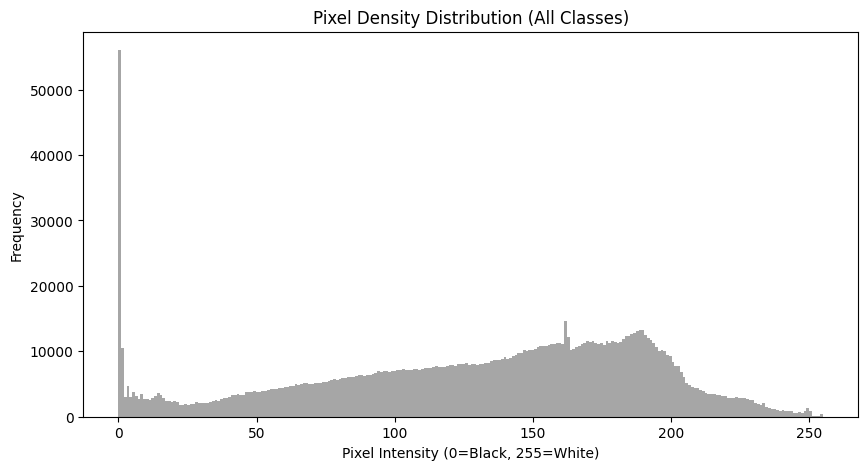

2026-02-23 22:55:06.399249: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [31]:
import matplotlib.pyplot as plt
import numpy as np

# Take one batch (i.e., 32 images)
for images, labels in train_ds.take(1):
    # Flatten all pixels in the batch into a 1D array
    pixels = images.numpy().flatten()
    
    plt.figure(figsize=(10, 5))
    plt.hist(pixels, bins=256, color='gray', alpha=0.7)
    plt.title('Pixel Density Distribution (All Classes)')
    plt.xlabel('Pixel Intensity (0=Black, 255=White)')
    plt.ylabel('Frequency')
    plt.show()

2026-02-23 22:55:06.709910: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


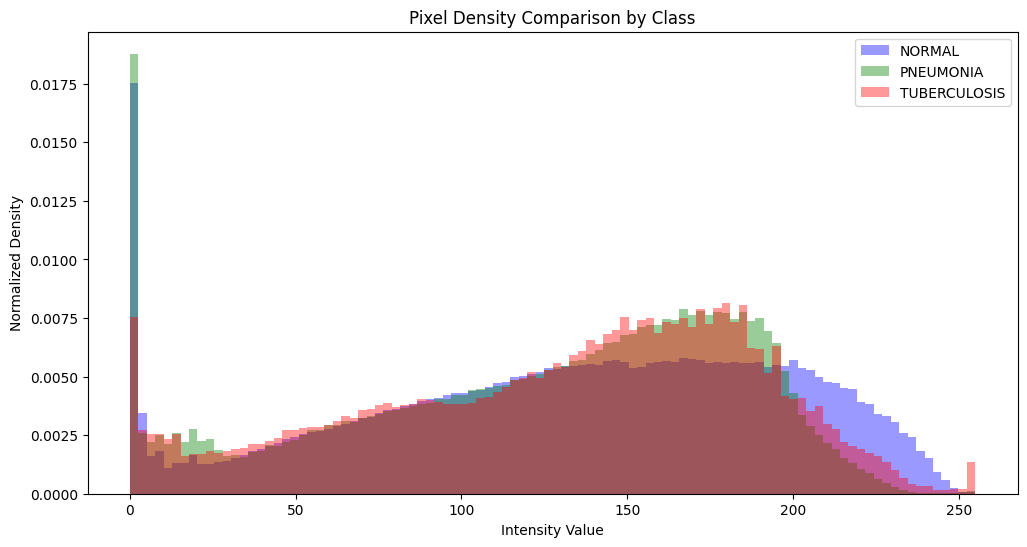

In [32]:
def plot_class_histograms(dataset, class_names):
    plt.figure(figsize=(12, 6))
    
    # Store pixels for each class
    class_pixels = {name: [] for name in class_names}
    
    # Analyze 5 batches
    for images, labels in dataset.take(5):
        images = images.numpy()
        labels = np.argmax(labels.numpy(), axis=1)
        
        for i in range(len(images)):
            cls_name = class_names[labels[i]]
            # Add flattened pixels of this specific image
            class_pixels[cls_name].extend(images[i].flatten())

    # Plotting
    colors = ['blue', 'green', 'red']
    for i, name in enumerate(class_names):
        plt.hist(class_pixels[name], bins=100, alpha=0.4, 
                 label=name, color=colors[i], density=True)

    plt.title('Pixel Density Comparison by Class')
    plt.xlabel('Intensity Value')
    plt.ylabel('Normalized Density')
    plt.legend()
    plt.show()

# Usage
plot_class_histograms(train_ds, train_ds.class_names)

In [ ]:
# Data Augmentation 
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05), # Small rotations only for medical images
    layers.RandomZoom(0.1),
])


#  Re-structured Model
model = models.Sequential([
    layers.Input(shape=(224, 224, 1)), 
    
    data_augmentation,
    layers.Rescaling(1./255),
    
    # Block 1
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Block 2
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Block 3
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Block 4 
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    
    # GAP reduces the 2D spatial maps into a single vector
    layers.GlobalAveragePooling2D(), 
    
    # Dense Head
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5), # Keep this high (0.5) to fight that overfitting
    layers.Dense(3, activation='softmax')
])



In [34]:
# Compile with a LOWER Learning Rate
# Default Adam is 0.001. Dropping to 0.0001 prevents the "Loss Explosion"
model.compile(
    optimizer=optimizers.AdamW,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

ValueError: Could not interpret optimizer identifier: <class 'keras.src.optimizers.adamw.AdamW'>

In [ ]:
# Save the model
model.save('CXC02.keras')
print("Model saved successfully!")

Model saved successfully!


In [ ]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.6006 - loss: 3.0543
Test Loss: 3.054346799850464
Test Accuracy: 60.06%


2026-02-23 22:53:02.407504: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


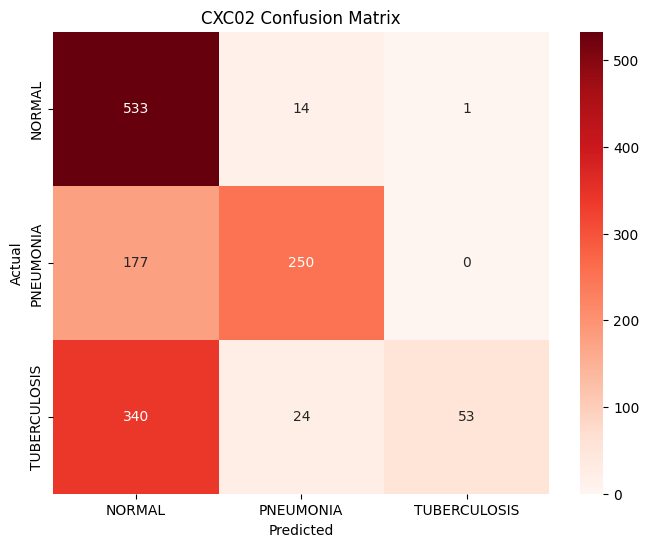

              precision    recall  f1-score   support

      NORMAL       0.51      0.97      0.67       548
   PNEUMONIA       0.87      0.59      0.70       427
TUBERCULOSIS       0.98      0.13      0.23       417

    accuracy                           0.60      1392
   macro avg       0.79      0.56      0.53      1392
weighted avg       0.76      0.60      0.54      1392



In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Get all predictions and true labels
y_pred = []
y_true = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels, axis=1))

# Generate the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
class_names = test_ds.class_names

# Plot them in heat map
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CXC02 Confusion Matrix')
plt.show()

# Print Precision, Recall, and F1-Score
print(classification_report(y_true, y_pred, target_names=class_names))

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf

# 1. Load the Test Dataset (Make sure shuffle=False for evaluation!)
test_ds = tf.keras.utils.image_dataset_from_directory(
    '../../../data/test',
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical',
    shuffle=False  # CRITICAL: Do not shuffle for the Confusion Matrix
)

# 2. Load your saved model
model = tf.keras.models.load_model('CXC02.keras')

# 3. Get Predictions
print("Evaluating model...")
# This method is quiet and won't trigger the "End of Sequence" warning
predictions = model.predict(test_ds)
y_pred = np.argmax(predictions, axis=1)

# 4. Get True Labels
# We extract labels from the dataset manually
y_true = np.concatenate([y for x, y in test_ds], axis=0)
y_true = np.argmax(y_true, axis=1)

# 5. Generate metrics
class_names = test_ds.class_names
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# 6. Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix: Actual vs Predicted')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.show()

Found 2569 files belonging to 3 classes.
Evaluating model...


ValueError: Exception encountered when calling Sequential.call().

[1mInput 0 with name 'None' of layer 'conv2d_10' is incompatible with the layer: expected axis -1 of input shape to have value 1, but received input with shape (32, 224, 224, 3)[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=(32, 224, 224, 3), dtype=float32)
  • training=False
  • mask=None
  • kwargs=<class 'inspect._empty'>

In [ ]:
model = tf.keras.models.load_model('CXC02.keras')
print(model.input_shape)
# Verify the architecture
model.summary()

(None, 224, 224, 1)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_4 (Sequential)       │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,267,211 (4.83 MB)

 Trainable params: 422,083 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

 Optimizer params: 844,168 (3.22 MB)

In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image

def predict_single_image(img_path, model):
    # 1. Load and resize the image
    img = image.load_img(img_path, target_size=(224, 224), color_mode='grayscale')
    
    # 2. Convert to array and add batch dimension
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) 
    
    # 3. Predict
    predictions = model.predict(img_array)
    
    # 4. Get class names (assuming standard order: Normal, Pneumonia, TB)
    # Note: These usually follow alphabetical order of your folders
    class_names = ['Normal', 'Pneumonia', 'Tuberculosis']
    result = class_names[np.argmax(predictions)]
    confidence = np.max(predictions) * 100
    
    return result, confidence

# Usage:
label, score = predict_single_image('../../../data/test/normal/normal-921.jpg', model)
print(f"Prediction: {label} ({score:.2f}%)")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
Prediction: Normal (80.90%)
